from ast import Module
project 3- Iris Flower clustering

Model

K _ means clustering

In [121]:
import pandas as pd
df = pd.read_csv("/content/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species_number,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [122]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species_number,species
145,6.7,3.0,5.2,2.3,2,virginica
146,6.3,2.5,5.0,1.9,2,virginica
147,6.5,3.0,5.2,2.0,2,virginica
148,6.2,3.4,5.4,2.3,2,virginica
149,5.9,3.0,5.1,1.8,2,virginica


In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sepal_length    150 non-null    float64
 1   sepal_width     150 non-null    float64
 2   petal_length    150 non-null    float64
 3   petal_width     150 non-null    float64
 4   species_number  150 non-null    int64  
 5   species         150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [124]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width,species_number
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [125]:
print("rows",df.shape[0])
print("columns",df.shape[1])

rows 150
columns 6


In [126]:
iris_feature=df[[
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]].copy()

iris_feature.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [127]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species_number,0
species,0


In [128]:
df.duplicated().sum()

np.int64(1)

In [129]:
df.drop_duplicates(inplace=True)

In [130]:
df.duplicated().sum()

np.int64(0)

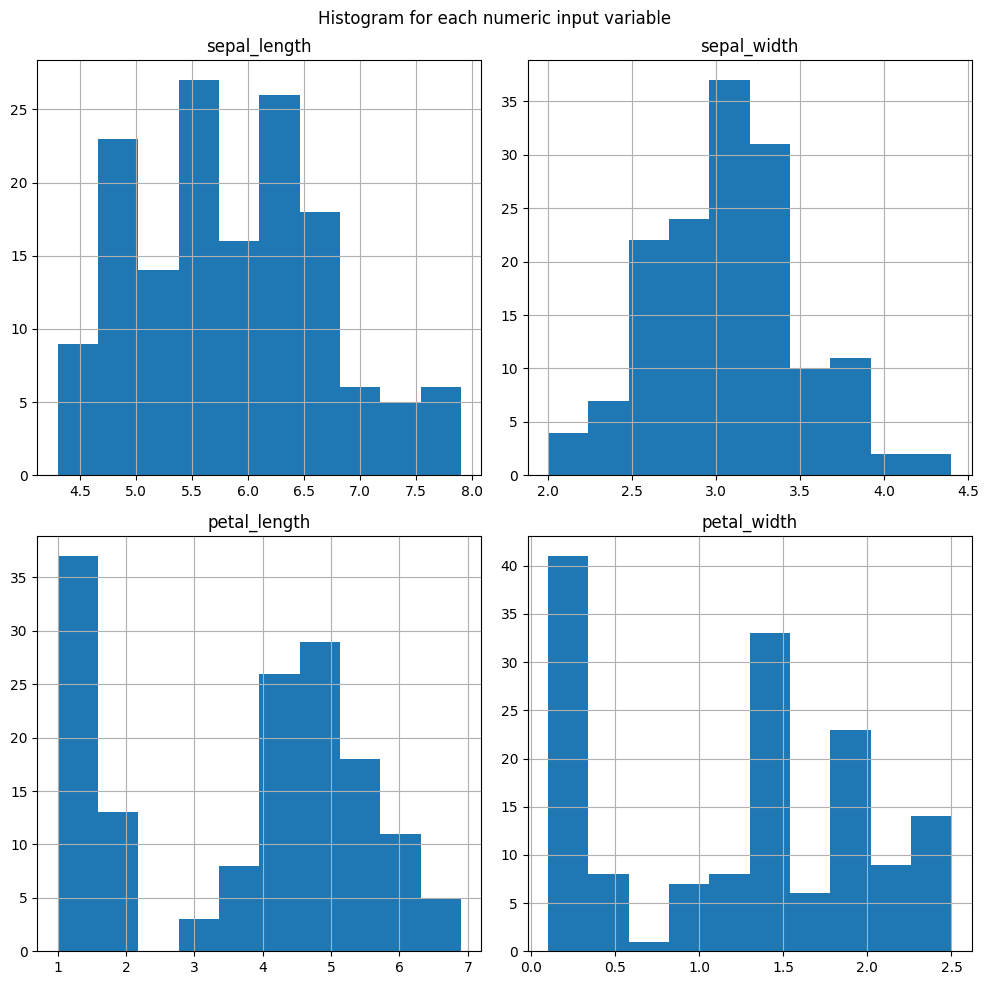

In [131]:
import matplotlib.pyplot as plt
iris_feature.hist(figsize=(10,10))
plt.suptitle("Histogram for each numeric input variable")
plt.tight_layout()
plt.show()

In [132]:
df.shape

(149, 6)

In [133]:
df.columns.tolist()

['sepal_length',
 'sepal_width',
 'petal_length',
 'petal_width',
 'species_number',
 'species']

In [134]:
from sklearn.preprocessing import StandardScaler
iris_scaler = StandardScaler()
iris_scaled = iris_scaler.fit_transform(iris_feature)

In [135]:
# USE Elbow method for k-means clustering
from sklearn.cluster import KMeans
inerty_values = []
for i in range(1,11):
    km = KMeans(n_clusters=i,n_init=10,random_state=42)
    km.fit(iris_scaled)
    inerty_values.append(km.inertia_)

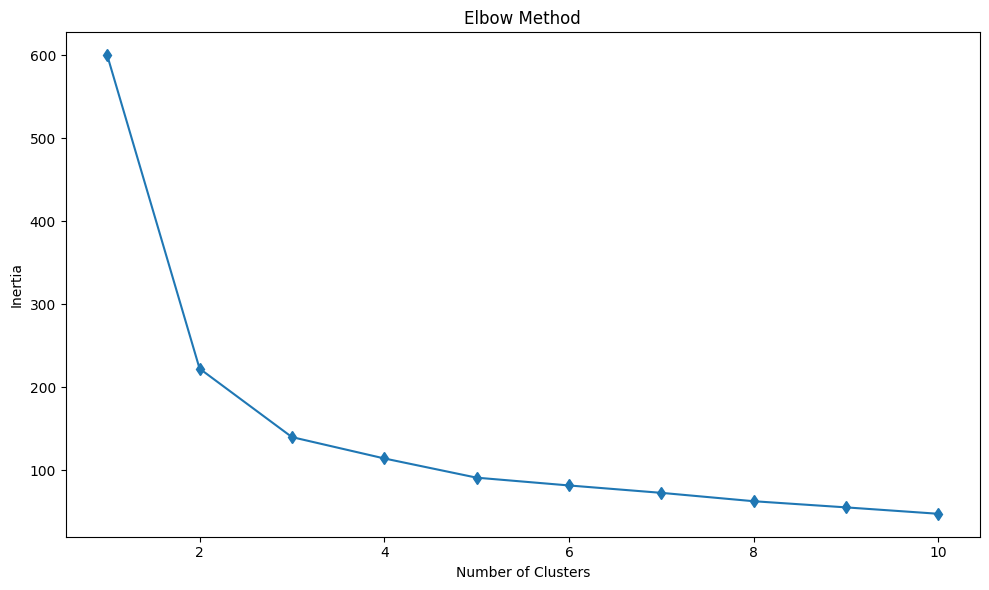

In [136]:
plt.figure(figsize=(10,6))
plt.plot(range(1,11),inerty_values,marker='d')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

In [137]:
#Train withe 3 clusters
Kmeans_model = KMeans(n_clusters=3,n_init=10,random_state=42)
iris_cluster = Kmeans_model.fit_predict(iris_scaled)


In [138]:
# 1. Extract and scale
iris_feature_clean = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].copy()
iris_scaled_clean = iris_scaler.fit_transform(iris_feature_clean)

# 2. Re-fit and predict
iris_cluster_clean = Kmeans_model.fit_predict(iris_scaled_clean)

# 3. Safely assign the cluster labels
iris_Cluster = df.copy()
iris_Cluster["cluster"] = iris_cluster_clean
iris_Cluster

,sepal_length,sepal_width,petal_length,petal_width,species_number,species,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,2
146,6.3,2.5,5.0,1.9,2,virginica,0
147,6.5,3.0,5.2,2.0,2,virginica,2
148,6.2,3.4,5.4,2.3,2,virginica,2


In [139]:
# plot clusters


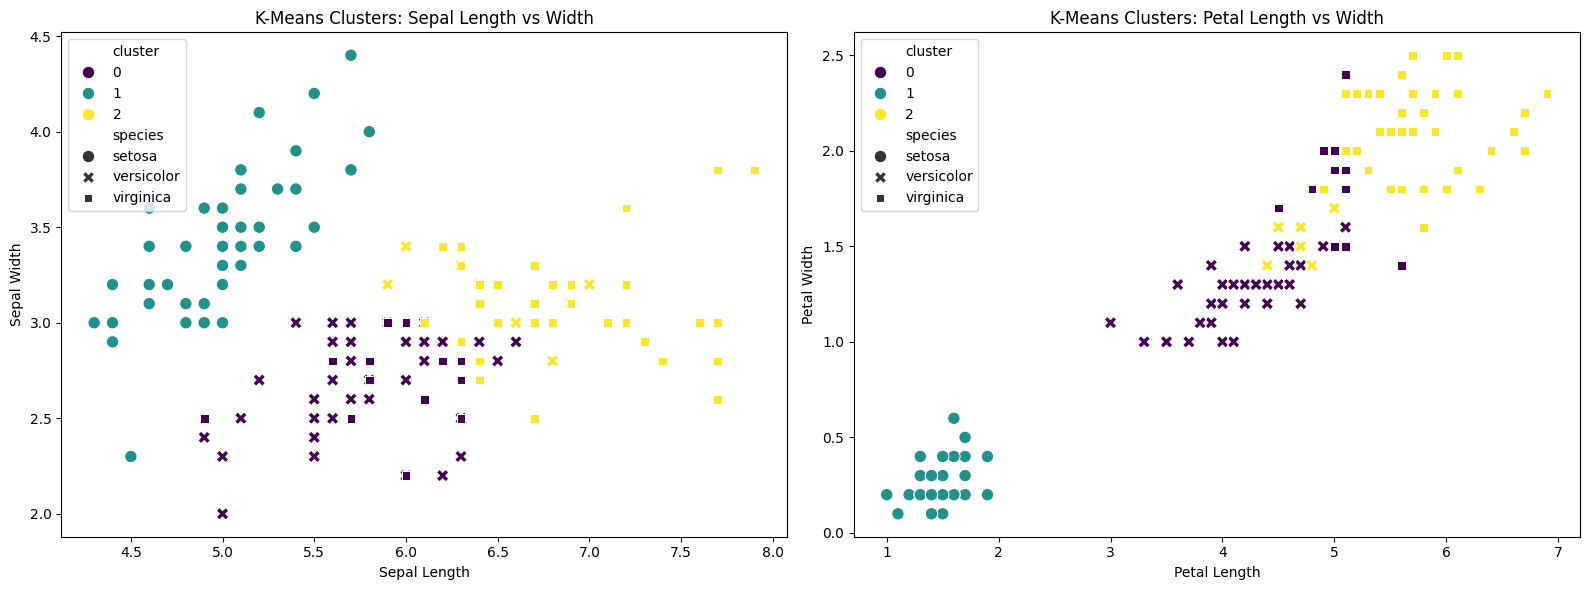

In [140]:
import seaborn as sns
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    ax=axes[0],
    data=iris_Cluster,
    x='sepal_length',
    y='sepal_width',
    hue='cluster',
    palette='viridis',
    style='species',
    s=80
)
axes[0].set_title('K-Means Clusters: Sepal Length vs Width')
axes[0].set_xlabel('Sepal Length')
axes[0].set_ylabel('Sepal Width')


sns.scatterplot(
    ax=axes[1],
    data=iris_Cluster,
    x='petal_length',
    y='petal_width',
    hue='cluster',
    palette='viridis',
    style='species',
    s=80
)
axes[1].set_title('K-Means Clusters: Petal Length vs Width')
axes[1].set_xlabel('Petal Length')
axes[1].set_ylabel('Petal Width')

plt.tight_layout()
plt.show()

evaluation metric for clsutering silhoutte score , db_index

In [141]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
score = silhouette_score(iris_scaled, iris_cluster)
print("Silhouette Score:", score)


Silhouette Score: 0.45994823920518646


In [142]:
score_db = davies_bouldin_score(iris_scaled, iris_cluster)
print("Davies-Bouldin Index:", score_db)

Davies-Bouldin Index: 0.8335949464754334


In [159]:
new_flower = pd.DataFrame({
    'sepal_length': [5.1],
    'sepal_width': [3.5],
    'petal_length': [1.4],
    'petal_width': [0.2]
})

new_flower

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


In [160]:
new_flower_scaled = iris_scaler.transform(new_flower)
new_flower_scaled

array([[-0.8980334 ,  1.01240113, -1.33325507, -1.30862368]])

In [161]:
new_flower_cluster = Kmeans_model.predict(new_flower_scaled)
print("Cluster of the new flower:", new_flower_cluster[0])

Cluster of the new flower: 1
